# Final-response semantic separation and illustrative trajectories

Two main panels only: A, role-separated persona-pair heatmaps; B, two question-controlled case studies. The user selected trial 1 only for all five settings: off/155/001/089/046. Panel A compares across-persona and within-persona final-response distances across distinct questions within super-family, with question-wise label-swap tests. Only the lower triangle is displayed; the diagonal is light gray and the redundant upper triangle is hidden. Heatmap axis lines, question-count headings, subtitles and bottom explanatory text are omitted from the graphic. Persona labels and the colorbar remain; statistical definitions and caveats are documented in this notebook and the report. Panel B is unchanged. Existing figures remain separate.

[Candidate manuscript caption and complete figure handoff](SEMANTIC_FIGURE_CAPTION.md)

In [1]:
from pathlib import Path
import sys,json,csv
from IPython.display import display,Markdown,Image,Code
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code/semantic'))
import analyze,plot,final_response,final_report
c=analyze.config()
display(Markdown('```json\n'+json.dumps({k:c[k] for k in ['arms','labels','model_id','model_revision','display_rollout']},indent=2)+'\n```'))

```json
{
  "arms": [
    "persona_off",
    "candidate_155",
    "candidate_001",
    "candidate_089",
    "candidate_046"
  ],
  "labels": {
    "persona_off": "Persona off",
    "candidate_155": "Persona 155",
    "candidate_001": "Persona 001",
    "candidate_046": "Persona 046",
    "candidate_089": "Persona 089"
  },
  "model_id": "Qwen/Qwen3-Embedding-0.6B",
  "model_revision": "97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
  "display_rollout": 1
}
```

## Data and embedding provenance
Current messages are encoded independently for simulator and actor, without system prompts, profiles, metadata or repeated history. Frozen Qwen3-Embedding-0.6B local weights; last-token pooling; normalized vectors. Extraction/embedding are separate resumable steps so notebook reruns do not launch inference.

In [2]:
provenance=json.loads((analyze.OUT/'provenance.json').read_text())
print('Original base extraction message count:',provenance['message_count'])
print('Original base extraction complete episodes:',provenance['eligible_episodes'])
print('Additional persona 089 extraction:',json.loads((analyze.OUT/'persona_089_embedding_provenance.json').read_text())['messages'],'messages')
print(json.dumps(json.loads((analyze.CACHE/'embedding_provenance.json').read_text()),indent=2))

Original base extraction message count: 11211
Original base extraction complete episodes: 2025
Additional persona 089 extraction: 1087 messages
{
  "model_id": "Qwen/Qwen3-Embedding-0.6B",
  "revision": "97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3",
  "torch": "2.13.0+cu130",
  "transformers": "5.14.1",
  "device": "cuda",
  "dtype": "float16",
  "pooling": "last nonpadding token",
  "l2_normalized": true,
  "instruction": null,
  "truncation": false,
  "unique_messages": 12153,
  "message_rows": 12298,
  "model_files": {
    "config.json": "b5bf1f51fc45be473a54718cef92448d90a1be001bf9b9a44b8c7f10a19feaa9",
    "tokenizer_config.json": "253153d0738ceb4c668d2eff957714dd2bea0b56de772a9fdccd96cbf517e6a0"
  },
  "cache_key": "fixed model revision + SHA256 of exact outer-whitespace-stripped message; runtime configuration recorded",
  "base_message_rows": 11211,
  "additions": [
    {
      "persona": "candidate_089",
      "trial": 1,
      "provenance_file": "Experiment/01_behavioral_diversit

## Aggregate before projection
Select the last nonempty generated message per role from each complete trial-1 interaction. Use a common question set across all five personas and both roles. Within each super-family, compare cross-persona distances across distinct questions with the two within-persona means across distinct questions. Average four family effects equally. No same-question distances enter the statistic. Swap persona labels within questions for 10,000 one-sided permutations; apply Holm correction across 20 tests. Bootstrap whole questions within benchmark × family 20,000 times for pointwise 95% CIs, retaining all personas and excluding same-original-question pairs even for duplicated sampled questions.

In [3]:
RECOMPUTE=False  # Set True to rerun permutations and bootstrap from cached embeddings.
if RECOMPUTE or not (final_response.DEST/'summary.json').exists(): final_response.main()
saved=json.loads((final_response.DEST/'summary.json').read_text())
summary=saved['roles']
final_report.main()
display(Markdown('```json\n'+json.dumps(saved['methods'],indent=2)+'\n```'))
print(json.dumps({role:{k:v for k,v in values.items() if k in ['questions','source_counts','family_counts']} for role,values in summary.items()},indent=2))

```json
{
  "endpoint": "Last nonempty generated role message among the saved simulator\u2013actor exchanges in a complete original trial-1 episode. Simulator may be a closing message; actor may be its last handoff/question/specification. Not necessarily a successful task submission. Roles may end at different rounds.",
  "question_set": "Common complete five-persona question set for BOTH roles. One final message per persona/question/role.",
  "statistic": "Within each super-family: mean cosine distance across ordered distinct-question cross-persona pairs minus half the sum of the two within-persona distinct-question means. Exclude same question pairs from both quantities. Average four family effects equally (25% each).",
  "permutation": "Independently swap the two persona labels within each question; keep family, benchmark and question identities fixed. This preserves question dependence without using same-question distances. One-sided alternative: cross-persona excess > 0. Monte Carlo p=(1+number of permuted statistics >= observed)/(10000+1).",
  "bootstrap": "Resample whole questions within source benchmark \u00d7 super-family; retain all five persona outputs together. 20000 resamples, percentile pointwise 95% CI. Exclude pairs representing the same original question even if selected twice; multiplicity-weight the remaining pairs and renormalize. Stratum sizes fixed.",
  "multiplicity": "Holm correction across all 20 role \u00d7 persona-pair tests. Family-specific estimates and CIs are descriptive, without additional significance testing.",
  "null": "Pairwise persona-label exchangeability within each question. Tests association under this null, not causality or rollout variability.",
  "limitations": "Within-persona spread includes question differences. One observed trial; bootstrap conditions on it. Source-study dependence beyond question is not modeled. Final-message functions and lengths vary by source/persona. Persona panel and endpoint were selected during exploratory analysis; results require confirmatory validation.",
  "permutations": 10000,
  "bootstrap_resamples": 20000,
  "seed": 20261008
}
```

{
  "simulator": {
    "questions": 158,
    "family_counts": {
      "life": 42,
      "physical_engineering": 46,
      "math_cs": 45,
      "social_humanities": 25
    },
    "source_counts": {
      "asibench": 17,
      "bixbench": 37,
      "discoverybench": 31,
      "expbench": 36,
      "sciconvbench": 37
    }
  },
  "actor": {
    "questions": 158,
    "family_counts": {
      "life": 42,
      "physical_engineering": 46,
      "math_cs": 45,
      "social_humanities": 25
    },
    "source_counts": {
      "asibench": 17,
      "bixbench": 37,
      "discoverybench": 31,
      "expbench": 36,
      "sciconvbench": 37
    }
  }
}


In [4]:
rows=list(csv.DictReader((final_response.DEST/'heatmap_cells.csv').open()))
for role in c['roles']:
    text=['### '+role,'','| Pair | Excess [95% CI] | Holm p | Questions |','|---|---|---:|---:|']
    for r in rows:
        if r['role']==role:
            text.append(f"| {c['labels'][r['persona_i']]} / {c['labels'][r['persona_j']]} | {float(r['estimate']):.4f} [{float(r['ci_low']):.4f}, {float(r['ci_high']):.4f}] | {float(r['p_holm']):.5f} | {r['questions']} |")
    display(Markdown('\n'.join(text)))

### simulator

| Pair | Excess [95% CI] | Holm p | Questions |
|---|---|---:|---:|
| Persona off / Persona 155 | 0.0249 [0.0227, 0.0270] | 0.00200 | 158 |
| Persona off / Persona 001 | 0.0263 [0.0231, 0.0295] | 0.00200 | 158 |
| Persona off / Persona 089 | 0.0003 [-0.0008, 0.0013] | 0.38596 | 158 |
| Persona off / Persona 046 | 0.0293 [0.0261, 0.0326] | 0.00200 | 158 |
| Persona 155 / Persona 001 | 0.0330 [0.0298, 0.0362] | 0.00200 | 158 |
| Persona 155 / Persona 089 | 0.0238 [0.0218, 0.0257] | 0.00200 | 158 |
| Persona 155 / Persona 046 | 0.0408 [0.0374, 0.0441] | 0.00200 | 158 |
| Persona 001 / Persona 089 | 0.0239 [0.0206, 0.0271] | 0.00200 | 158 |
| Persona 001 / Persona 046 | 0.0257 [0.0225, 0.0289] | 0.00200 | 158 |
| Persona 089 / Persona 046 | 0.0277 [0.0246, 0.0307] | 0.00200 | 158 |

### actor

| Pair | Excess [95% CI] | Holm p | Questions |
|---|---|---:|---:|
| Persona off / Persona 155 | 0.0164 [0.0145, 0.0182] | 0.00200 | 158 |
| Persona off / Persona 001 | 0.0093 [0.0077, 0.0110] | 0.00200 | 158 |
| Persona off / Persona 089 | 0.0001 [-0.0004, 0.0007] | 0.38596 | 158 |
| Persona off / Persona 046 | 0.0163 [0.0146, 0.0180] | 0.00200 | 158 |
| Persona 155 / Persona 001 | 0.0145 [0.0129, 0.0161] | 0.00200 | 158 |
| Persona 155 / Persona 089 | 0.0159 [0.0141, 0.0175] | 0.00200 | 158 |
| Persona 155 / Persona 046 | 0.0199 [0.0181, 0.0216] | 0.00200 | 158 |
| Persona 001 / Persona 089 | 0.0095 [0.0080, 0.0111] | 0.00200 | 158 |
| Persona 001 / Persona 046 | 0.0139 [0.0123, 0.0156] | 0.00200 | 158 |
| Persona 089 / Persona 046 | 0.0162 [0.0146, 0.0178] | 0.00200 | 158 |

## Case studies and plotting
Persona 089 is an exploratory replacement chosen after inspecting the 004 results. The user manually selected bix-57-q1 and matToolUse/disambiguation/case_236 after reviewing the long-interaction gallery. These are illustrative, not representative examples. Rollout 1 is displayed for every persona and both roles; UMAP is refitted after replacing persona 004 with 089, using the same two cases and parameters: cosine metric, up to 15 neighbors, min_dist=0.1, 500 epochs and seed 42. All five settings jointly define each question–role map. Actual lengths, nodes and final markers are retained. Directional arrows are omitted. Gentle quadratic curves connect consecutive observed nodes for visual clarity; intermediate positions do not represent observed states. The control-point offset is 0.14 times the perpendicular chord in axis-normalized coordinates; endpoints are fixed. Point indices are omitted from the figure; round indices remain in source data. Local projections are not comparable across plots.

```json
[
  {
    "source": "bixbench",
    "task_id": "bix-57-q1",
    "display_rollout": 1,
    "selection": "User-selected after exploratory long-interaction UMAP review"
  },
  {
    "source": "sciconvbench",
    "task_id": "matToolUse/disambiguation/case_236",
    "display_rollout": 1,
    "selection": "User-selected after exploratory long-interaction UMAP review"
  }
]

```

#!/usr/bin/env python3
"""Only A: pairwise heatmaps and B: two question-controlled trajectory cases."""
import csv
import json
from pathlib import Path
import sys
import textwrap
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.font_manager import FontProperties
from matplotlib.transforms import Bbox
from matplotlib.path import Path as MplPath
from matplotlib.text import Text
from analyze import BASE,OUT,config,write_csv,NAMES
sys.path.insert(0,'/home/siyangwu/.codex/skills/nature-figure/scripts')
from audit_panel_alignment import require_matplotlib_panel_alignment
FIG=BASE/'figures/semantic'
PLACEMENTS=[]
COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'axes.labelsize':6,'axes.titlesize':6,'xtick.labelsize':5.5,'ytick.labelsize':5.5,'svg.fonttype':'none','pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.6})

def place_round_labels(ax,specs,segments,context):
    """Place every real round label near its node, avoiding text and paths."""
    fig=ax.figure;fig.canvas.draw();renderer=fig.canvas.get_renderer()
    font=FontProperties(size=5.3);scale=fig.dpi/72
    extent=ax.get_window_extent();placed=[];drawn=[]
    nodes=np.array([ax.transData.transform(s[0]) for s in specs])
    lines=[MplPath(ax.transData.transform(np.array([a,b]))) for a,b in segments]
    lines.extend(t.arrow_patch.get_path().transformed(t.arrow_patch.get_transform()) for t in ax.texts if getattr(t,'arrow_patch',None) is not None)
    for node,text,color in specs:
        center=ax.transData.transform(node)
        width,height,_=renderer.get_text_width_height_descent(text,font,False)
        height=5.3*scale*1.3
        candidates=[]
        minimum_radius={('simulator','bix-43-q5','#0072B2','13'):20,('simulator','bix-43-q5','#0072B2','11'):16,('simulator','bix-43-q5','#D55E00','2'):16,('actor','fluids/disambiguation/case_001','#D55E00','4'):16}.get((*context,color,text),7)
        for radius in [r for r in [7,10,13,16,20,24,28] if r>=minimum_radius]:
            for angle in np.arange(0,360,30):
                offset=np.array([np.cos(np.deg2rad(angle)),np.sin(np.deg2rad(angle))])*radius*scale
                pos=center+offset
                rect=Bbox.from_bounds(pos[0]-width/2-2*scale,pos[1]-height/2-2*scale,width+4*scale,height+4*scale)
                outside=not(extent.contains(rect.x0,rect.y0) and extent.contains(rect.x1,rect.y1))
                overlap=sum(rect.overlaps(b) for b in placed)
                node_box=rect.expanded(1+6*scale/rect.width,1+6*scale/rect.height)
                on_node=sum(node_box.contains(*n) for n in nodes)
                crosses=sum(path.intersects_bbox(rect,filled=False) for path in lines)
                leader=MplPath(np.array([center+offset/radius*3.5,pos-offset/radius*5]))
                leader_crosses=sum(leader.intersects_bbox(b,filled=False) for b in placed) if radius>8 else 0
                score=1e9*outside+1e8*overlap+1e6*on_node+1e5*leader_crosses+1e5*crosses+radius
                candidates.append((score,angle,radius,offset,rect))
        _,_,radius,offset,rect=min(candidates,key=lambda c:(c[0],c[1]))
        forced={('simulator','bix-43-q5','#009E73','1'):(-16,25),('simulator','bix-43-q5','#0072B2','12'):(-25,25),('actor','fluids/disambiguation/case_001','#0072B2','3'):(-20,10),('actor','fluids/disambiguation/case_001','#009E73','3'):(14,25),('actor','fluids/disambiguation/case_001','#D55E00','3'):(-14,28)}.get((*context,color,text))
        if forced:
            offset=np.array(forced)*scale;radius=float(np.linalg.norm(offset)/scale);pos=center+offset
            rect=Bbox.from_bounds(pos[0]-width/2-2*scale,pos[1]-height/2-2*scale,width+4*scale,height+4*scale)
        placed

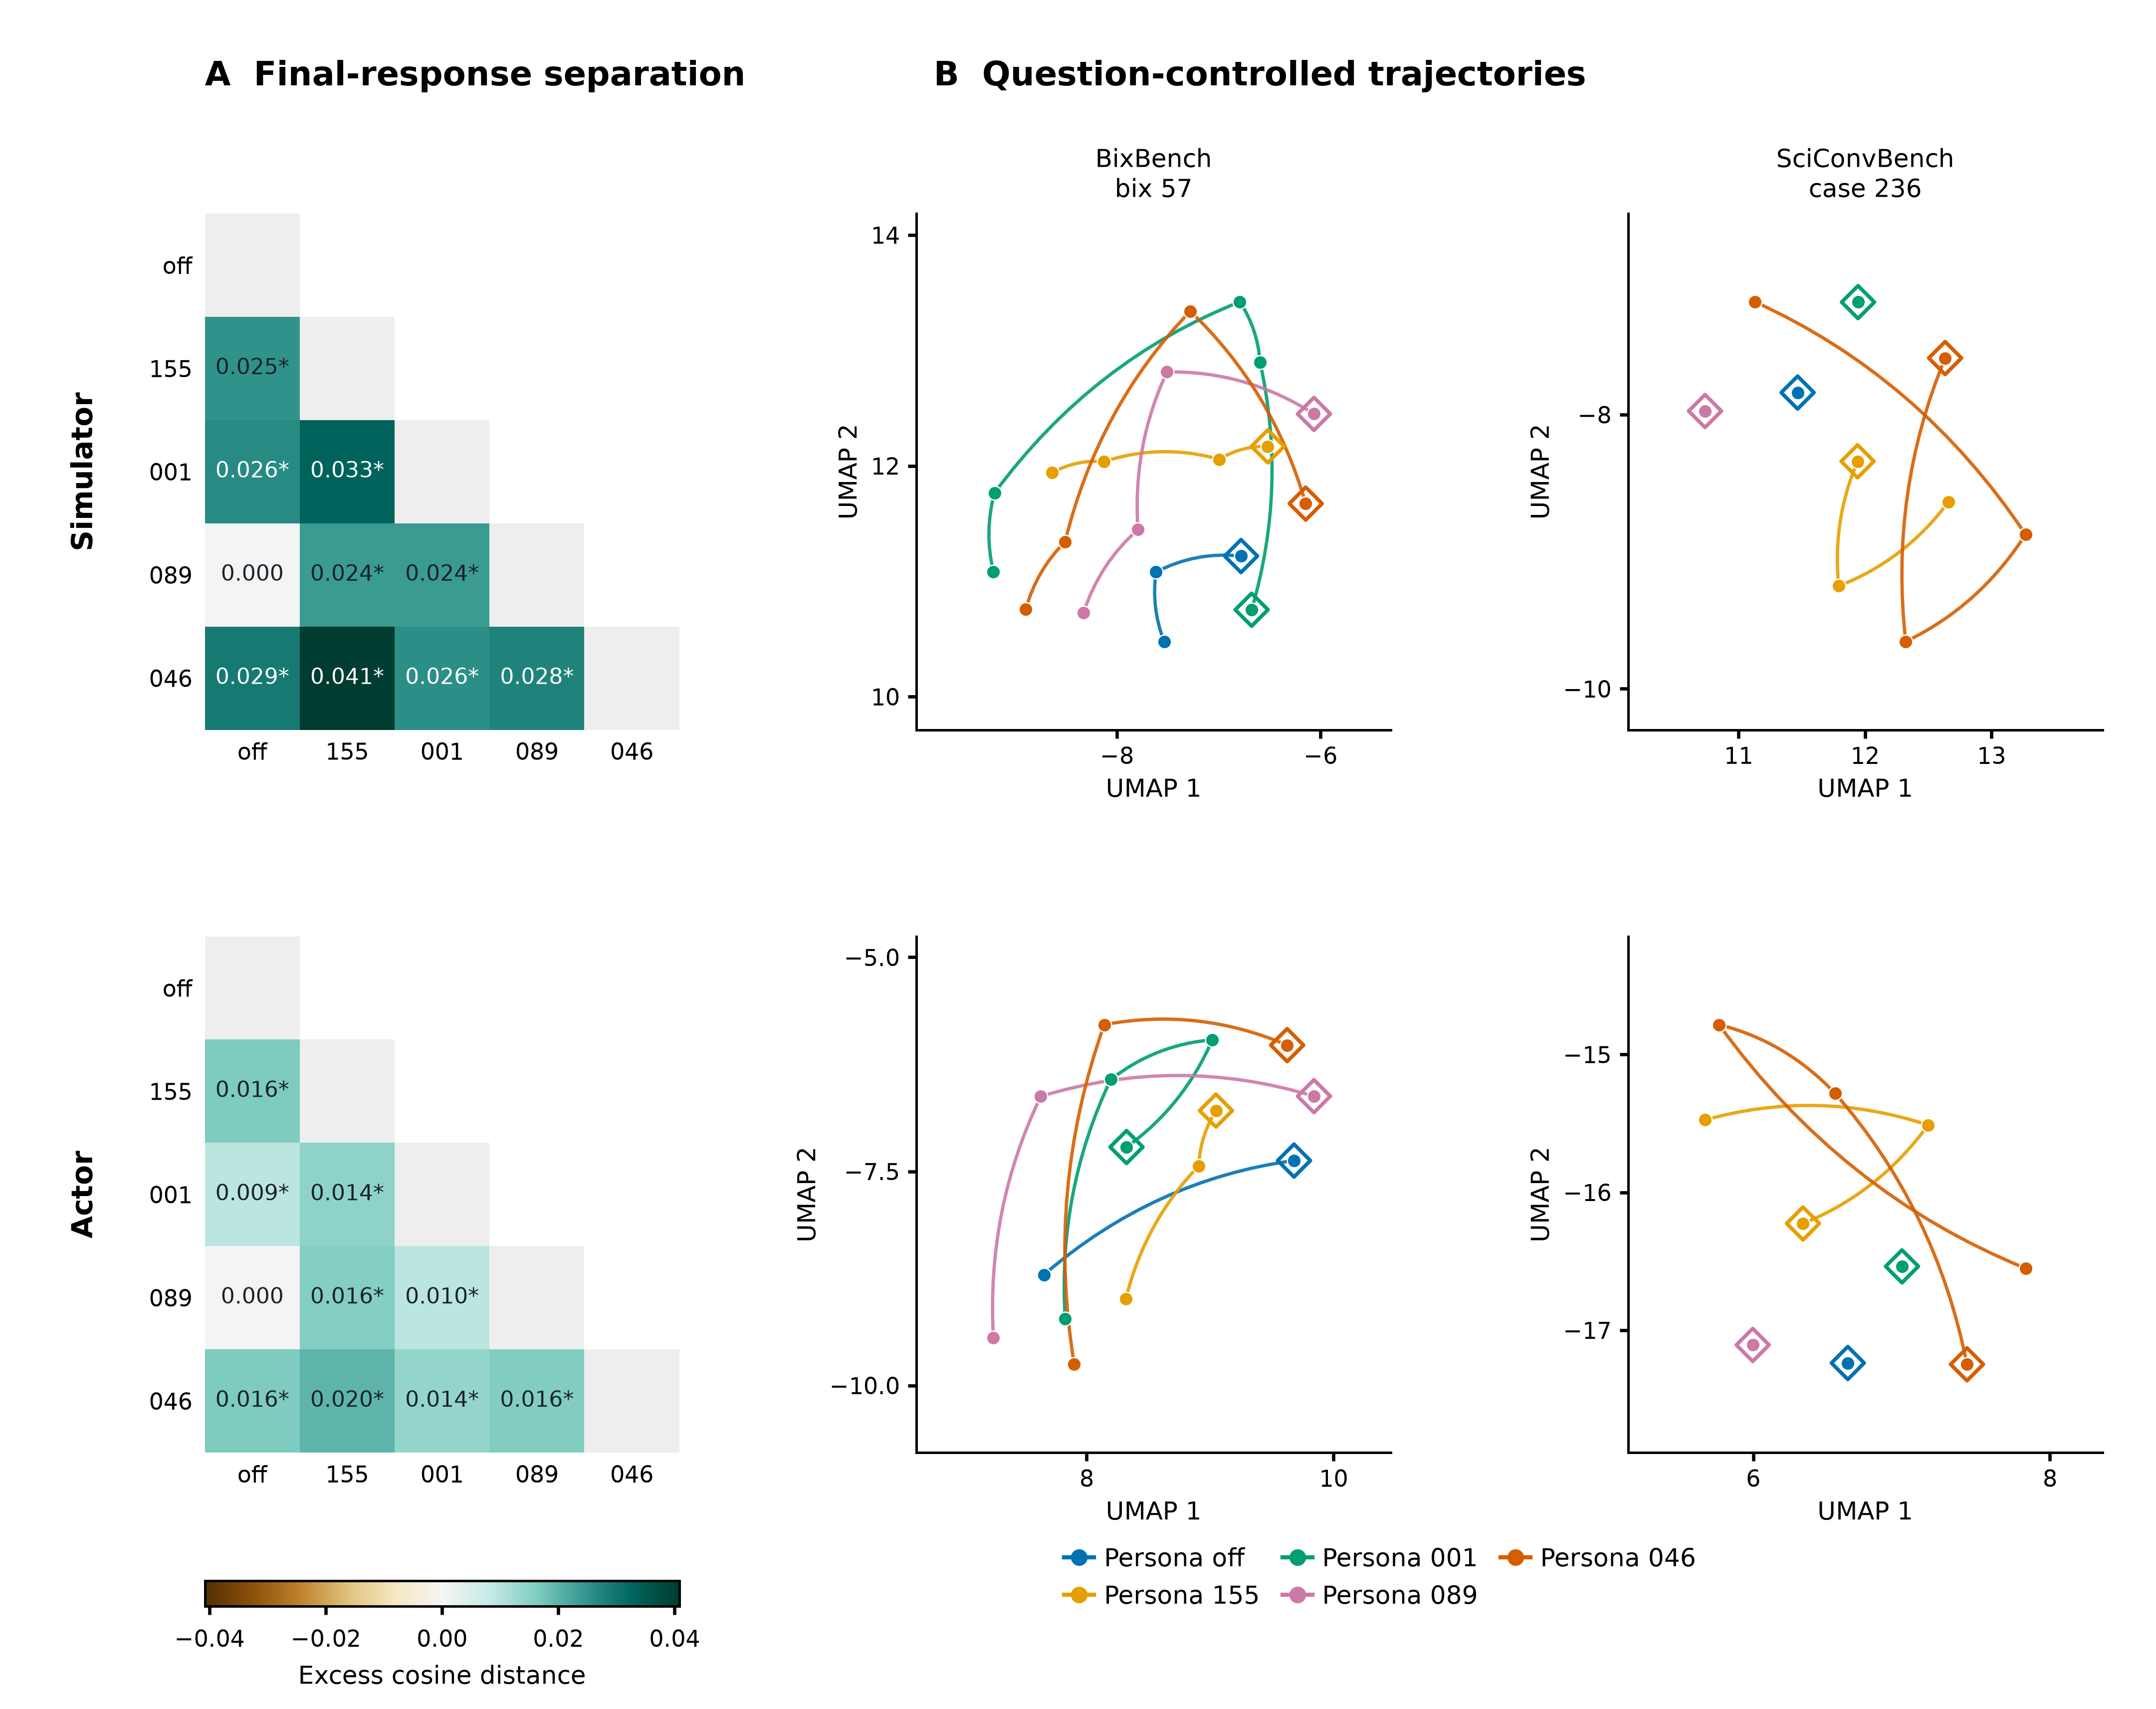

In [5]:
display(Markdown('```json\n'+(analyze.OUT/'cases.json').read_text()+'\n```'))
display(Code(Path(plot.__file__).read_text(),language='python'))
plot.main()
display(Image(filename=str(plot.FIG/'semantic.png'),width=1200))

In [6]:
import numpy as np
for role,v in summary.items():
    m=np.asarray(v['estimate']);assert np.allclose(m,m.T)
    assert np.all(np.diag(m)==0)
    assert np.isfinite(m).all()
assert len(rows)==10*len(c['roles'])
assert all(float(r['p_holm'])>=float(r['p_permutation'])-1e-12 for r in rows)
assert len({v['questions'] for v in summary.values()})==1
coords=list(csv.DictReader((analyze.OUT/'trajectory_coordinates.csv').open()))
shown=[r for r in coords if r['displayed']=='True']
assert {int(r['trial']) for r in shown}=={c['display_rollout']}
assert {r['arm'] for r in shown}==set(c['arms'])
print('Validated: symmetric heatmaps, ten comparisons per role, fixed displayed rollout, all five settings, finite estimates.')

Validated: symmetric heatmaps, ten comparisons per role, fixed displayed rollout, all five settings, finite estimates.


## Interpretation
Panel A is aggregate evidence scoped to the matched selected questions. Panel B is illustrative. Within-persona spread includes differences across questions, not repeated-rollout randomness. Inference is conditional on the observed trial and question-wise exchangeability. Stars use Holm-adjusted one-sided permutation p<0.05; CIs are pointwise and need not agree with adjusted decisions. This is an exploratory analysis. Language/style can affect distance; neither cosine distance nor a UMAP path measures task or reasoning quality. Full intervals, exact p values, source/family counts and endpoint definitions are in `SEMANTIC_REPORT.md`.